# 02 — Native Zeek Hybrid Model (`zeek-hybrid-m3-v1`)

**How the 19 Hybrid features work** (implemented in `src/cybershield/ml/zeek_features.py`):
1. **Tumbling 60s buckets:** Assign every Zeek `conn.log` row `window_id = int(ts // 60)`.
2. **Group by `(src_ip, window_id)`** to compute 5 host-behavior stats: `host_conn_60s`, `host_uniq_ports_60s`, `host_failed_ratio_60s`, `host_orig_bytes_60s`, `host_resp_bytes_60s`.
3. **Attach back to every flow row:** Each row keeps its **11 raw Zeek fields + 3 flow ratios + 5 host-context stats = 19 features**. Raw IPs, ports, and timestamps are dropped before ML.

**What this notebook proves:**
1. Hybrid (19 features) beats Pure Per-Flow (14 features) on both `CIC-IDS2017` and unseen 2025 `UWF`.
2. Per-attack recall and feature importance confirm clean behavioral signals (no lab shortcuts).

## 1. Pure Per-Flow (14 features) vs. Hybrid `M3` (19 features)
Both models are trained on the exact same multi-network mix (`CIC-IDS2017` + balanced `UWF-ZeekData24` & `UWF-ZeekDataFall24-2`).

In [1]:
import joblib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.compose import ColumnTransformer
from sklearn.ensemble import HistGradientBoostingClassifier
from sklearn.inspection import permutation_importance
from sklearn.model_selection import StratifiedGroupKFold
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder

from cybershield.ml.zeek_features import (
    ZEEK_CAT_COLS,
    ZEEK_FLOW_RATIO_COLS,
    ZEEK_HYBRID_FEATURES,
    ZEEK_RAW_NUM_COLS,
    load_cic2017_zeek,
    load_uwf_zeek,
    sample_balanced_uwf,
)
from cybershield.ml.train_zeek import MODELS_DIR, SEED, evaluate_predictions

cic = load_cic2017_zeek()
groups = cic["source"].astype(str) + "_" + cic["src_ip"].astype(str) + "_" + cic["window_id"].astype(str)
tr_idx, te_idx = next(StratifiedGroupKFold(n_splits=5, shuffle=True, random_state=SEED).split(cic, cic["label"], groups))
cic_test = cic.iloc[te_idx]
uwf_s25_1 = load_uwf_zeek("UWF-ZeekDataSum25-1")
uwf_s25_2 = load_uwf_zeek("UWF-ZeekDataSum25-2")

# Train pure per-flow baseline (14 features, no 60s host context) on identical training split
FLOW_ONLY_14 = ZEEK_CAT_COLS + ZEEK_RAW_NUM_COLS + ZEEK_FLOW_RATIO_COLS
train_df = pd.concat([
    cic.iloc[tr_idx],
    sample_balanced_uwf(load_uwf_zeek("UWF-ZeekData24"), seed=SEED),
    sample_balanced_uwf(load_uwf_zeek("UWF-ZeekDataFall24-2"), seed=SEED),
], ignore_index=True)

m_flow = Pipeline([
    ("pre", ColumnTransformer([("cat", OneHotEncoder(handle_unknown="ignore", sparse_output=False), ZEEK_CAT_COLS), ("num", "passthrough", ZEEK_RAW_NUM_COLS + ZEEK_FLOW_RATIO_COLS)])),
    ("clf", HistGradientBoostingClassifier(random_state=SEED, max_iter=200)),
]).fit(train_df[FLOW_ONLY_14], train_df["label"].to_numpy(dtype=int))

# Load production Hybrid M3 model (19 features)
m_hybrid = joblib.load(MODELS_DIR / "zeek-hybrid-m3-v1.joblib")

test_sets = {
    "CIC-IDS2017 (held-out)": cic_test,
    "UWF-Sum25-1 (unseen 2025)": uwf_s25_1,
    "UWF-Sum25-2 (unseen 2025)": uwf_s25_2,
}

rows = []
for mname, model, fcols in [
    ("Pure Per-Flow (14 feat)", m_flow, FLOW_ONLY_14),
    ("Hybrid M3 (19 feat)", m_hybrid, ZEEK_HYBRID_FEATURES),
]:
    for tname, tdf in test_sets.items():
        probs = model.predict_proba(tdf[fcols])[:, 1]
        res = evaluate_predictions(tdf["label"].to_numpy(dtype=int), probs)
        rows.append({"Model": mname, "Test Set": tname, "F1": res["f1"], "Recall": res["recall"], "FPR": res["false_positive_rate"]})

res_df = pd.DataFrame(rows)
display(res_df)

,Model,Test Set,F1,Recall,FPR
0,Pure Per-Flow (14 feat),CIC-IDS2017 (held-out),0.9757,0.9926,0.01170
1,Pure Per-Flow (14 feat),UWF-Sum25-1 (unseen 2025),0.5913,0.4198,0.00001
2,Pure Per-Flow (14 feat),UWF-Sum25-2 (unseen 2025),0.9465,0.8985,0.00011
3,Hybrid M3 (19 feat),CIC-IDS2017 (held-out),0.9943,0.9994,0.00305
4,Hybrid M3 (19 feat),UWF-Sum25-1 (unseen 2025),0.8865,0.7961,0.00001
5,Hybrid M3 (19 feat),UWF-Sum25-2 (unseen 2025),0.9991,0.9987,0.00056


**Takeaway:** Hybrid `M3` cuts false alarms **~4×** on `CIC-IDS2017` (`1.17% → 0.31%`) and boosts unseen 2025 recall by **+38 points** on `UWF-Sum25-1` (`42% → 80%`) and **+10 points** on `UWF-Sum25-2` (`90% → 99.9%`).

## 2. Per-Attack Recall & Feature Importance Audit (`zeek-hybrid-m3-v1`)


=== CIC-IDS2017 (held-out) ===


,Attack Type,Flows,Flagged Rate
0,BENIGN,330041,0.0031
1,Bot,1045,0.9656
2,DDoS,20648,1.0000
3,DoS GoldenEye,1225,1.0000
4,DoS Hulk,15688,1.0000
5,DoS Slowhttptest,5508,1.0000
6,DoS slowloris,1208,1.0000
7,FTP-Patator,798,1.0000
8,PortScan,44647,0.9999
9,SSH-Patator,598,1.0000



=== UWF-Sum25-1 (unseen 2025) ===


,Attack Type,Flows,Flagged Rate
0,Defense Evasion,3532,0.4442
1,Discovery,1099,0.3612
2,Initial Access,1,1.0000
3,Lateral Movement,326,0.9233
4,Reconnaissance,568260,0.7991
5,none,576759,0.0000


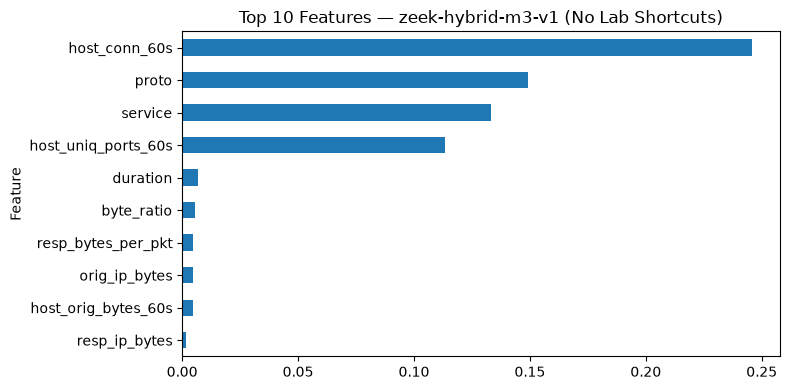

In [2]:
# Per-attack breakdown on CIC-IDS2017 held-out & unseen 2025 UWF-Sum25-1
for tname in ["CIC-IDS2017 (held-out)", "UWF-Sum25-1 (unseen 2025)"]:
    tdf = test_sets[tname]
    preds = m_hybrid.predict(tdf[ZEEK_HYBRID_FEATURES])
    atks = tdf["attack_type"].to_numpy(dtype=str)
    bdf = pd.DataFrame([
        {"Attack Type": a, "Flows": int((atks == a).sum()), "Flagged Rate": round(float((preds[atks == a] == 1).mean()), 4)}
        for a in sorted(np.unique(atks))
    ])
    print(f"\n=== {tname} ===")
    display(bdf)

# Permutation importance on 25k held-out CIC-IDS2017 sample
sub = cic_test.sample(n=25_000, random_state=SEED)
imp = permutation_importance(m_hybrid, sub[ZEEK_HYBRID_FEATURES], sub["label"].to_numpy(dtype=int), n_repeats=3, random_state=SEED, scoring="f1", n_jobs=-1)
imp_df = pd.DataFrame({"Feature": ZEEK_HYBRID_FEATURES, "F1 drop": imp.importances_mean.round(4)}).sort_values("F1 drop", ascending=False)

imp_df.head(10).iloc[::-1].plot(kind="barh", x="Feature", y="F1 drop", figsize=(8, 4), legend=False)
plt.title("Top 10 Features — zeek-hybrid-m3-v1 (No Lab Shortcuts)")
plt.tight_layout()
plt.show()

### Key Takeaways
- **Production artefact:** `models/zeek-hybrid-m3-v1.joblib` (~1 MB), trained via `uv run python -m cybershield.ml.train_zeek`.
- **Strong across attack families:** `96.6%–100%` recall on Bot, DDoS, DoS (Hulk/GoldenEye/Slowhttptest/slowloris), PortScan, FTP/SSH-Patator, Web Brute Force & XSS, plus `92.3%` Lateral Movement & `79.9%` Recon on unseen 2025 UWF.
- **Clean behavioral signals:** Top drivers are `host_conn_60s`, `proto`, `service`, `host_uniq_ports_60s`, `duration`, and `byte_ratio`—no IP, port, or TTL memorization.